# MatSpat Tutorial — Happy Path

End-to-end walkthrough of the MatSpat analysis pipeline on synthetic data.

**Pipeline stages:**
1. Generate synthetic spatial data
2. Load & standardize with the preprocessing module
3. ICA-based tissue rotation (with before/after visualization)
4. Spatial descriptors — freud-based local density & structural features
5. Compute tumor–immune trajectories across tumor density zones
6. Partial correlation — control for local density (from descriptors)
7. Build multivariate HMM sequences
8. Train class-dependent HMMs & classify

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams["figure.dpi"] = 120

## 1. Generate synthetic data

We use `matspat.sample_data` to create 10 synthetic tissue images
(5 per disease class). The two classes have distinct spatial patterns:

- **inflamed**: immune cells cluster near the tumor core
- **excluded**: immune cells form a ring around the tumor

The data is written to a temporary CSV so we can test the full file-loading pathway.

In [2]:
from matspat.sample_data import generate_sample_dataset

raw_df = generate_sample_dataset(n_per_class=5, seed=42)

# Write to a temp CSV so we exercise the loader
tmp_dir = Path(tempfile.mkdtemp())
csv_path = tmp_dir / "sample_spatial_data.csv"
raw_df.to_csv(csv_path, index=False)

print(f"Generated {raw_df.image_id.nunique()} images, {len(raw_df)} cells total")
print(f"Saved to: {csv_path}")
raw_df.head()

Generated 10 images, 1923 cells total
Saved to: /tmp/tmp9171esil/sample_spatial_data.csv


,X,Y,cell_type,image_id,pathology
0,268.283025,187.600954,Tumor,excluded_01,excluded
1,295.027072,306.433883,Tumor,excluded_01,excluded
2,132.937889,171.869230,Tumor,excluded_01,excluded
3,257.670424,231.025444,Tumor,excluded_01,excluded
4,248.991931,198.817364,Tumor,excluded_01,excluded


## 2. Load & standardize

`load_spatial_data()` maps arbitrary column names to MatSpat's canonical schema
and encodes cell types as integers.

In [3]:
from matspat.preprocessing import load_spatial_data

df, cell_type_map = load_spatial_data(
    csv_path,
    x_col="X",
    y_col="Y",
    cell_type_col="cell_type",
    image_id_col="image_id",
    pathology_col="pathology",
)

print("Cell type encoding:", cell_type_map)
print(f"Shape: {df.shape}")
df.head()

Cell type encoding: {'CD4': 1, 'CD8': 2, 'Macrophage': 3, 'Tumor': 4}
Shape: (1923, 7)


,cell_id,x,y,cell_type,cell_type_encoded,image_id,pathology
0,1,268.283025,187.600954,Tumor,4,excluded_01,excluded
1,2,295.027072,306.433883,Tumor,4,excluded_01,excluded
2,3,132.937889,171.869230,Tumor,4,excluded_01,excluded
3,4,257.670424,231.025444,Tumor,4,excluded_01,excluded
4,5,248.991931,198.817364,Tumor,4,excluded_01,excluded


## 3. ICA rotation

`process_rotation()` fits ICA on tumor cell coordinates and rotates the entire
tissue so the dominant tumor axis points north (+Y). This standardizes
orientation across samples.

In [4]:
from matspat.preprocessing import process_rotation

# Rotate each image independently
rotated_frames = []
for image_id, img_df in df.groupby("image_id"):
    rotated_frames.append(process_rotation(img_df, tumor_label="Tumor"))

df = pd.concat(rotated_frames, ignore_index=True)

print("Added columns:", [c for c in df.columns if "rot" in c])
df[["image_id", "cell_type", "x", "y", "x_rot", "y_rot"]].head()

Added columns: ['x_rot', 'y_rot']


/home/npkamath/mambaforge/envs/matspat/lib/python3.11/site-packages/sklearn/decomposition/_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/home/npkamath/mambaforge/envs/matspat/lib/python3.11/site-packages/sklearn/decomposition/_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


,image_id,cell_type,x,y,x_rot,y_rot
0,excluded_01,Tumor,268.283025,187.600954,-118.240321,305.268940
1,excluded_01,Tumor,295.027072,306.433883,-227.272433,359.569102
2,excluded_01,Tumor,132.937889,171.869230,-135.225312,170.075364
3,excluded_01,Tumor,257.670424,231.025444,-162.942800,305.313687
4,excluded_01,Tumor,248.991931,198.817364,-133.731951,289.207696


### Before vs. after rotation

Compare one **excluded** and one **inflamed** image before and after ICA
alignment. After rotation the dominant tumor axis should point upward.

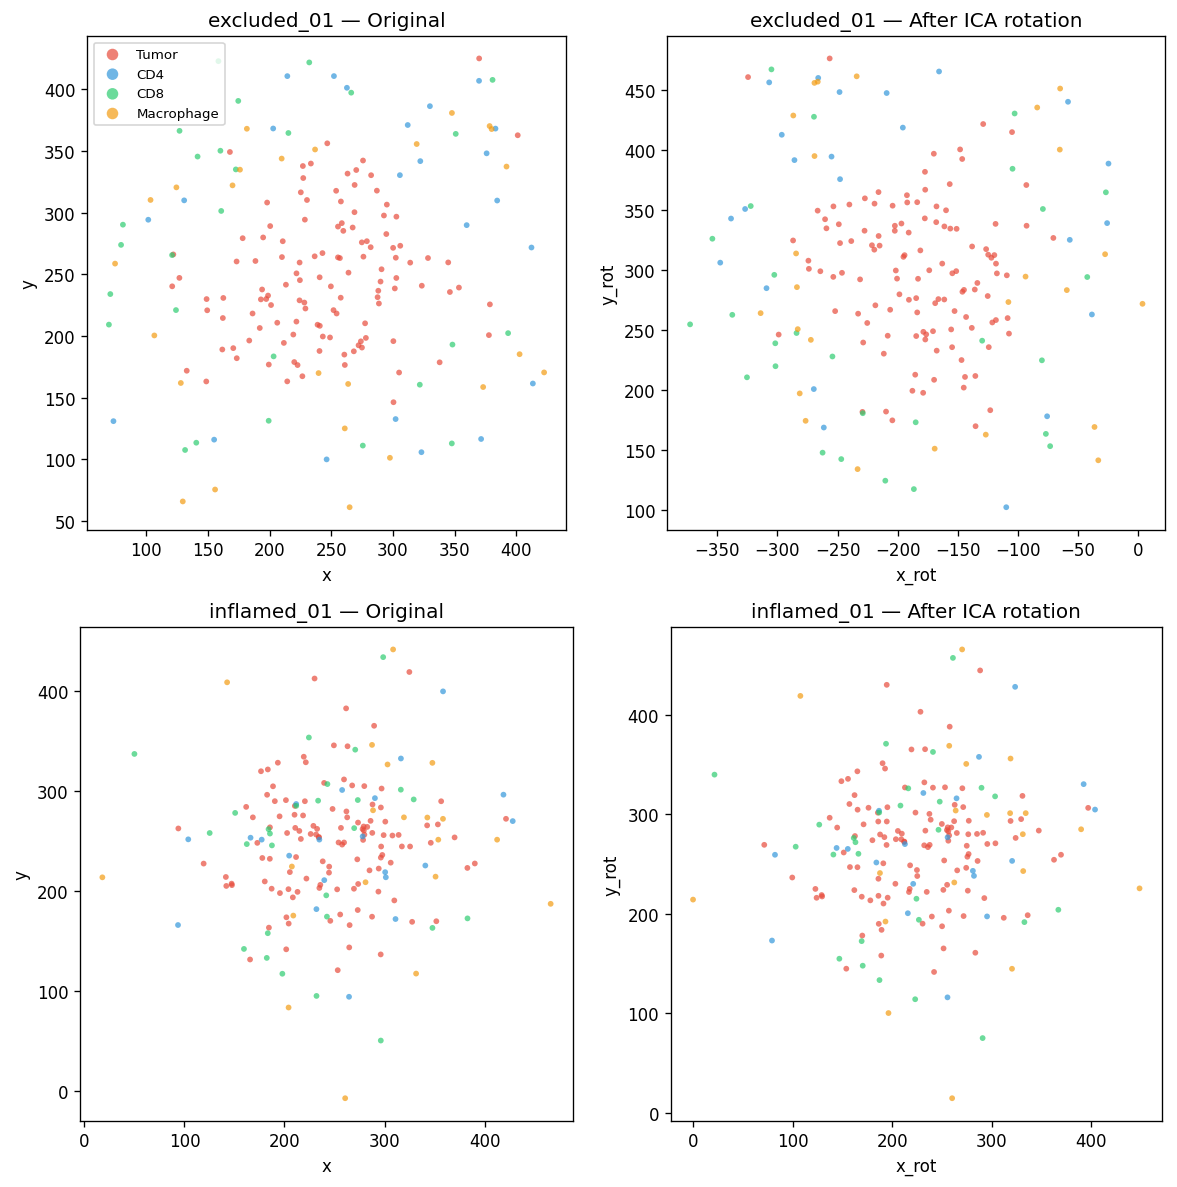

In [5]:
CELL_COLORS = {"Tumor": "#e74c3c", "CD4": "#3498db", "CD8": "#2ecc71", "Macrophage": "#f39c12"}
sample_images = ["excluded_01", "inflamed_01"]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for row, img_id in enumerate(sample_images):
    img = df[df["image_id"] == img_id]
    for col, (xcol, ycol, title_suffix) in enumerate(
        [("x", "y", "Original"), ("x_rot", "y_rot", "After ICA rotation")]
    ):
        ax = axes[row, col]
        for ct, color in CELL_COLORS.items():
            mask = img["cell_type"] == ct
            ax.scatter(
                img.loc[mask, xcol],
                img.loc[mask, ycol],
                c=color,
                label=ct,
                s=12,
                alpha=0.7,
                edgecolors="none",
            )
        ax.set_title(f"{img_id} — {title_suffix}")
        ax.set_xlabel(xcol)
        ax.set_ylabel(ycol)
        ax.set_aspect("equal")
        if row == 0 and col == 0:
            ax.legend(fontsize=8, markerscale=2)

fig.tight_layout()
plt.show()

## 4. Spatial descriptors (freud)

The `descriptors` module uses [freud](https://freud.readthedocs.io/) to compute
per-cell structural features: local density, k-atic orientational order, and
neighbor cell-type counts.

These features capture local tissue architecture independently of the KDE
pipeline. We'll use the **local density** as a structural covariate for
partial correlation later.

In [6]:
from matspat.descriptors import (
    compute_katic_order,
    compute_local_density,
    count_neighbor_cell_types,
)

# Descriptors expect canonical "x", "y" columns — use rotated coordinates
desc_df = df.rename(columns={"x": "x_orig", "y": "y_orig", "x_rot": "x", "y_rot": "y"})

R_MAX = 60.0  # neighbor search radius (same spatial units as coordinates)

# Local density per cell (all cell types participate in neighbor list)
density_df = compute_local_density(desc_df, r_max=R_MAX, include_neighbor_counts=True)
print("Local density:")
print(density_df.head())

# Hexatic order |ψ_6| — measures local 6-fold symmetry of cell arrangement
order_df = compute_katic_order(desc_df, k=6, r_max=R_MAX)
print("\nHexatic order (k=6):")
print(order_df.head())

# Neighbor cell-type counts within r_max
neighbor_counts = count_neighbor_cell_types(desc_df, r_max=R_MAX)
print("\nNeighbor type counts:")
print(neighbor_counts.head())

Local density:
   cell_id     image_id cell_type  local_density  num_neighbors
0        1  excluded_01     Tumor       0.003006             34
1        2  excluded_01     Tumor       0.002829             32
2        3  excluded_01     Tumor       0.000973             11
3        4  excluded_01     Tumor       0.004686             53
4        5  excluded_01     Tumor       0.003714             42

Hexatic order (k=6):
   cell_id     image_id cell_type     psi_6
0        1  excluded_01     Tumor  0.106461
1        2  excluded_01     Tumor  0.130340
2        3  excluded_01     Tumor  0.284497
3        4  excluded_01     Tumor  0.128123
4        5  excluded_01     Tumor  0.109730



Neighbor type counts:
   cell_id     image_id cell_type  n_neighbors_CD4  n_neighbors_CD8  \
0        1  excluded_01     Tumor                0                1   
1        2  excluded_01     Tumor                2                0   
2        3  excluded_01     Tumor                0                2   
3        4  excluded_01     Tumor                0                0   
4        5  excluded_01     Tumor                0                1   

   n_neighbors_Macrophage  n_neighbors_Tumor  
0                       2                 31  
1                       1                 29  
2                       2                  7  
3                       0                 53  
4                       2                 39  


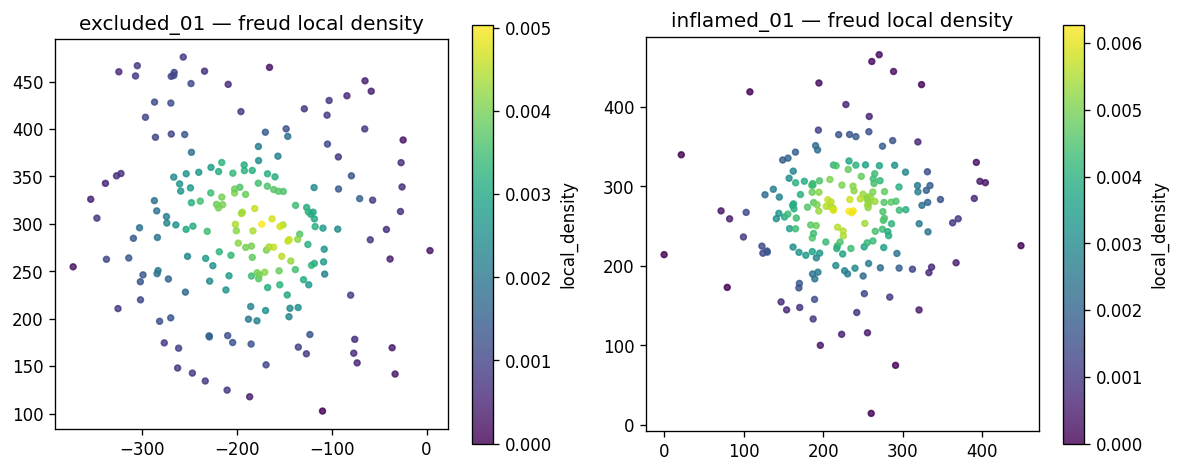

In [7]:
# Visualize local density for one image per disease class
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, img_id in zip(axes, ["excluded_01", "inflamed_01"]):
    img_density = density_df[density_df["image_id"] == img_id]
    img_coords = desc_df[desc_df["image_id"] == img_id]
    merged = img_coords[["cell_id", "x", "y", "cell_type"]].merge(
        img_density[["cell_id", "local_density"]], on="cell_id"
    )
    sc = ax.scatter(
        merged["x"], merged["y"], c=merged["local_density"], s=12, cmap="viridis", alpha=0.8
    )
    ax.set_title(f"{img_id} — freud local density")
    ax.set_aspect("equal")
    plt.colorbar(sc, ax=ax, label="local_density")

fig.tight_layout()
plt.show()

## 5. Tumor–immune trajectories

`compute_pairwise_trajectories()` does the heavy lifting:
- Builds a tumor KDE per image
- Partitions the density surface into quantile bins
- Computes Lee's L between tumor density and each immune cell type within each bin

The default `pair_mode="tumor_immune"` gives one trajectory per immune type,
measuring how each immune population co-localizes with tumor across the
density gradient (core → periphery).

Other modes: `"immune_immune"` (all immune–immune pairs) or `"all"` (both).

In [8]:
from matspat.interactions import compute_pairwise_trajectories

BANDWIDTH = 50.0
N_QUANTILES = 4
GRID_SIZE = 50

trajectories = compute_pairwise_trajectories(
    df,
    tumor_label="Tumor",
    bandwidth=BANDWIDTH,
    n_quantiles=N_QUANTILES,
    quantile_method="marginal",
    grid_size=GRID_SIZE,
    # pair_mode="tumor_immune" is the default
)

print(f"Trajectory rows: {len(trajectories)}")
print(f"Pairs: {trajectories['immune_pair'].unique().tolist()}")
trajectories.head(12)

Trajectory rows: 120
Pairs: ['Tumor x CD4', 'Tumor x CD8', 'Tumor x Macrophage']


,image_id,immune_pair,quantile_bin,lees_L
0,excluded_01,Tumor x CD4,0,0.758886
1,excluded_01,Tumor x CD4,1,-0.047377
2,excluded_01,Tumor x CD4,2,-0.052551
3,excluded_01,Tumor x CD4,3,-0.467933
4,excluded_01,Tumor x CD8,0,0.367796
5,excluded_01,Tumor x CD8,1,0.071701
6,excluded_01,Tumor x CD8,2,-0.018127
7,excluded_01,Tumor x CD8,3,-0.542106
8,excluded_01,Tumor x Macrophage,0,0.471909
9,excluded_01,Tumor x Macrophage,1,-0.068249


### Trajectory visualization

Lee's L across tumor density quantile bins, averaged per disease class.
Each line traces how a tumor–immune pair's co-localization changes as we
move from low to high tumor density regions.

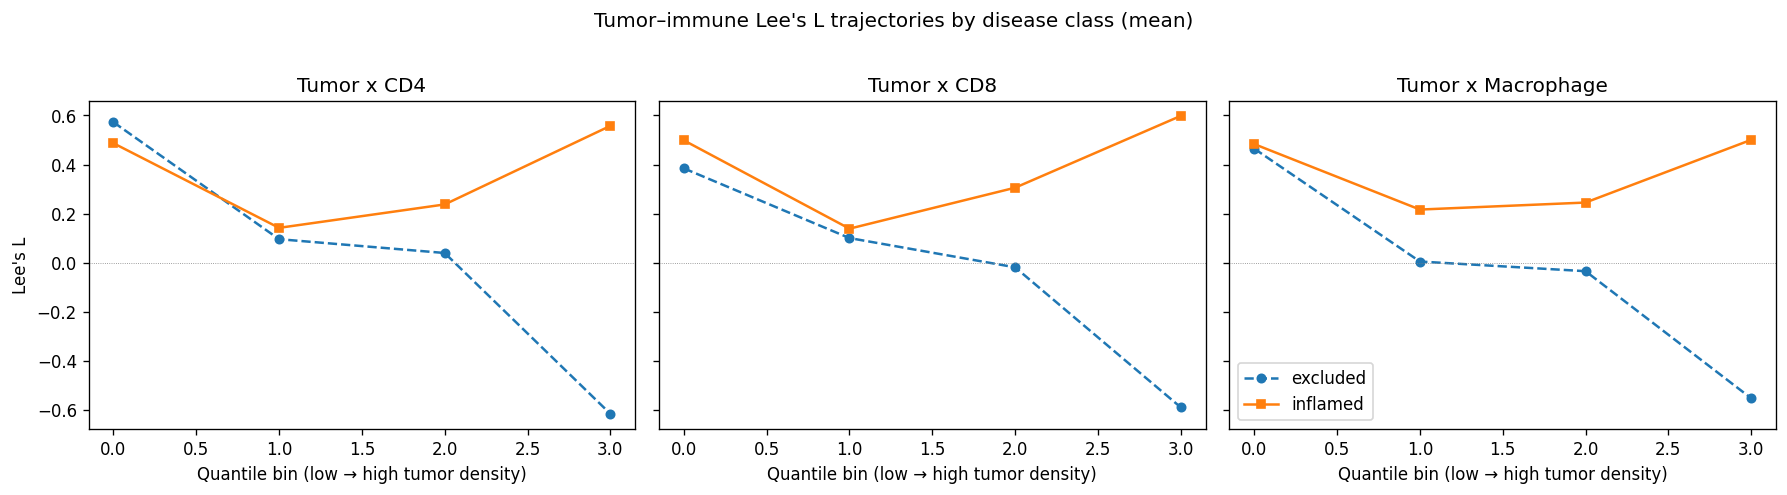

In [9]:
# Attach disease labels to trajectories for grouping
image_disease = df[["image_id", "pathology"]].drop_duplicates().set_index("image_id")["pathology"]
trajectories["disease"] = trajectories["image_id"].map(image_disease)

immune_pairs = sorted(trajectories["immune_pair"].unique())

fig, axes = plt.subplots(1, len(immune_pairs), figsize=(5 * len(immune_pairs), 4), sharey=True)

for ax, pair in zip(axes, immune_pairs):
    for disease, style in [("excluded", "--o"), ("inflamed", "-s")]:
        sub = trajectories[
            (trajectories["immune_pair"] == pair) & (trajectories["disease"] == disease)
        ]
        mean_traj = sub.groupby("quantile_bin")["lees_L"].mean()
        ax.plot(mean_traj.index, mean_traj.values, style, label=disease, markersize=5)
    ax.set_title(pair)
    ax.set_xlabel("Quantile bin (low \u2192 high tumor density)")
    ax.axhline(0, color="grey", linewidth=0.5, linestyle=":")

axes[0].set_ylabel("Lee's L")
axes[-1].legend()
fig.suptitle("Tumor\u2013immune Lee's L trajectories by disease class (mean)", y=1.02)
fig.tight_layout()
plt.show()

## 6. Partial correlation — controlling for local density

Lee's L can be confounded by overall tissue density: areas with many cells
may show high co-localization simply because *everything* is dense there.

**GWPCor** (Geographically Weighted Partial Correlation) removes the linear
effect of a structural covariate before computing the spatial correlation.
Here we use the **freud-computed local density** from step 4 as covariate `z`,
interpolated onto the KDE grid via `interpolate_to_grid()`.

The workflow:
1. Build a shared grid per image
2. Compute KDE for tumor and each immune type
3. Interpolate per-cell freud local density onto the grid (covariate z)
4. Partition grid by tumor density quantiles
5. Run `gwpcor_sequence()` instead of `lees_L_sequence()`

In [10]:
from sklearn.neighbors import KernelDensity

from matspat.density import build_grid, get_marginal_quantile_masks
from matspat.interactions import gwpcor_sequence, interpolate_to_grid, lees_L_sequence

gwpcor_rows = []
lees_l_rows = []  # recompute Lee's L on same grid for fair comparison

for image_id, img_df in df.groupby("image_id"):
    all_coords = img_df[["x_rot", "y_rot"]].values
    tumor_coords = img_df.loc[img_df["cell_type"] == "Tumor", ["x_rot", "y_rot"]].values

    if tumor_coords.shape[0] < 2:
        continue

    # Shared grid
    _xs, _ys, grid_pts = build_grid(all_coords, GRID_SIZE)

    # Tumor KDE -> quantile masks + flat density
    tumor_kde = KernelDensity(bandwidth=BANDWIDTH).fit(tumor_coords)
    tumor_flat = np.exp(tumor_kde.score_samples(grid_pts))
    tumor_2d = tumor_flat.reshape(GRID_SIZE, GRID_SIZE)
    masks = get_marginal_quantile_masks(tumor_2d, N_QUANTILES)
    masks_list = [masks[i] for i in range(N_QUANTILES)]

    # Covariate z: freud local density interpolated onto the grid
    img_density = density_df[density_df["image_id"] == image_id]
    img_desc = desc_df[desc_df["image_id"] == image_id]
    merged_z = img_desc[["cell_id", "x", "y"]].merge(
        img_density[["cell_id", "local_density"]], on="cell_id"
    )
    z_full = interpolate_to_grid(
        merged_z[["x", "y"]].values,
        merged_z["local_density"].values,
        grid_pts,
    )

    # Immune type KDEs
    immune_types = sorted(
        ct
        for ct in img_df["cell_type"].unique()
        if ct != "Tumor" and (img_df["cell_type"] == ct).sum() >= 2
    )

    immune_densities = {}
    for ct in immune_types:
        coords = img_df.loc[img_df["cell_type"] == ct, ["x_rot", "y_rot"]].values
        kde = KernelDensity(bandwidth=BANDWIDTH).fit(coords)
        immune_densities[ct] = np.exp(kde.score_samples(grid_pts))

    # Tumor–immune: GWPCor and Lee's L for each immune type
    for ct in immune_types:
        pair = f"Tumor x {ct}"

        gwp_vals = gwpcor_sequence(
            tumor_flat,
            immune_densities[ct],
            z_full,
            grid_pts,
            BANDWIDTH,
            masks_list,
        )
        lee_vals = lees_L_sequence(
            tumor_flat,
            immune_densities[ct],
            grid_pts,
            BANDWIDTH,
            masks_list,
        )

        for q, (gval, lval) in enumerate(zip(gwp_vals, lee_vals)):
            gwpcor_rows.append(
                {"image_id": image_id, "immune_pair": pair, "quantile_bin": q, "gwpcor": gval}
            )
            lees_l_rows.append(
                {"image_id": image_id, "immune_pair": pair, "quantile_bin": q, "lees_L": lval}
            )

gwpcor_df = pd.DataFrame(gwpcor_rows)
lees_l_df = pd.DataFrame(lees_l_rows)

print(f"GWPCor trajectory rows: {len(gwpcor_df)}")
gwpcor_df.head()

GWPCor trajectory rows: 120


,image_id,immune_pair,quantile_bin,gwpcor
0,excluded_01,Tumor x CD4,0,0.754276
1,excluded_01,Tumor x CD4,1,-0.092477
2,excluded_01,Tumor x CD4,2,-0.147398
3,excluded_01,Tumor x CD4,3,-0.361190
4,excluded_01,Tumor x CD8,0,0.451597


### Lee's L vs. GWPCor trajectories

Compare raw spatial correlation (Lee's L) with partial correlation (GWPCor)
that controls for freud-computed local density. Differences reveal where tissue
structure was inflating or masking the tumor–immune signal.

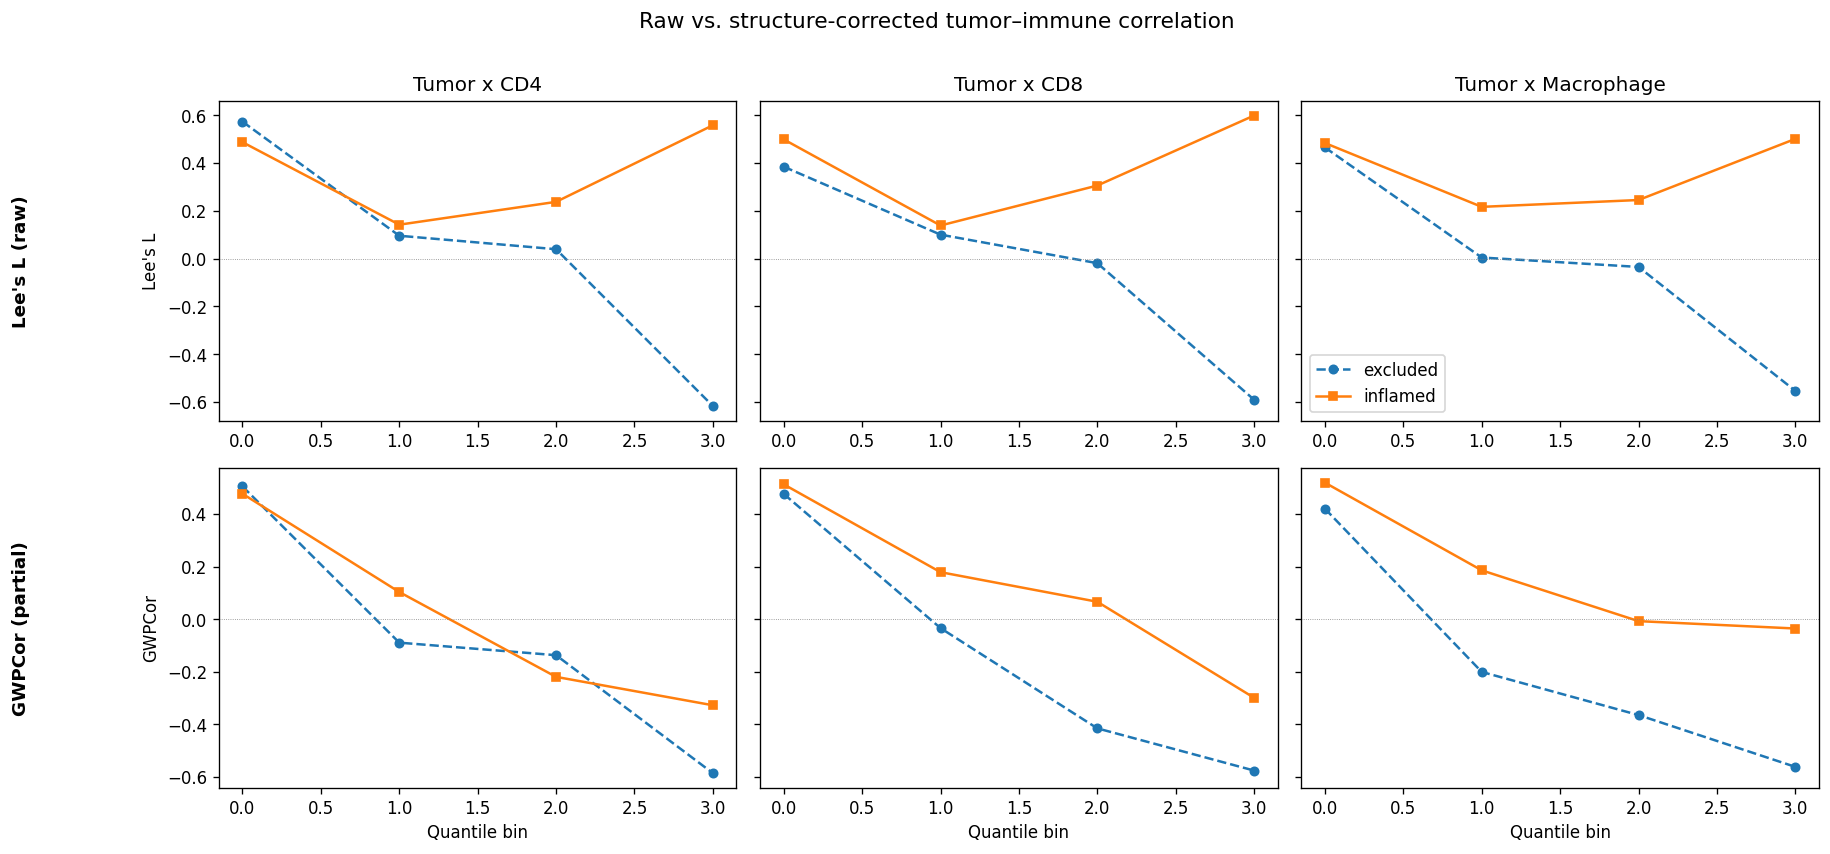

In [11]:
gwpcor_df["disease"] = gwpcor_df["image_id"].map(image_disease)
lees_l_df["disease"] = lees_l_df["image_id"].map(image_disease)

fig, axes = plt.subplots(2, len(immune_pairs), figsize=(5 * len(immune_pairs), 7), sharey="row")

for col, pair in enumerate(immune_pairs):
    # Top row: Lee's L
    ax = axes[0, col]
    for disease, style in [("excluded", "--o"), ("inflamed", "-s")]:
        sub = lees_l_df[(lees_l_df["immune_pair"] == pair) & (lees_l_df["disease"] == disease)]
        mean_traj = sub.groupby("quantile_bin")["lees_L"].mean()
        ax.plot(mean_traj.index, mean_traj.values, style, label=disease, markersize=5)
    ax.set_title(pair)
    ax.axhline(0, color="grey", linewidth=0.5, linestyle=":")
    if col == 0:
        ax.set_ylabel("Lee's L")

    # Bottom row: GWPCor
    ax = axes[1, col]
    for disease, style in [("excluded", "--o"), ("inflamed", "-s")]:
        sub = gwpcor_df[(gwpcor_df["immune_pair"] == pair) & (gwpcor_df["disease"] == disease)]
        mean_traj = sub.groupby("quantile_bin")["gwpcor"].mean()
        ax.plot(mean_traj.index, mean_traj.values, style, label=disease, markersize=5)
    ax.set_xlabel("Quantile bin")
    ax.axhline(0, color="grey", linewidth=0.5, linestyle=":")
    if col == 0:
        ax.set_ylabel("GWPCor")

axes[0, -1].legend()
axes[0, 0].annotate(
    "Lee's L (raw)",
    xy=(0, 0.5),
    xytext=(-0.4, 0.5),
    xycoords="axes fraction",
    textcoords="axes fraction",
    fontsize=11,
    fontweight="bold",
    va="center",
    rotation=90,
)
axes[1, 0].annotate(
    "GWPCor (partial)",
    xy=(0, 0.5),
    xytext=(-0.4, 0.5),
    xycoords="axes fraction",
    textcoords="axes fraction",
    fontsize=11,
    fontweight="bold",
    va="center",
    rotation=90,
)
fig.suptitle("Raw vs. structure-corrected tumor\u2013immune correlation", fontsize=13, y=1.01)
fig.tight_layout()
plt.show()

## 7. Build HMM sequences

Each image becomes a matrix of shape `(n_quantile_bins, n_immune_pairs)`.
The "time" axis represents progression through the tumor density gradient;
the features are Lee's L values for each tumor–immune pair.

In [12]:
from matspat.classification import build_sequences, extract_labels

sequences, feature_names = build_sequences(trajectories)

print(f"Sequences: {len(sequences)} images")
print(f"Features (tumor\u2013immune pairs): {feature_names}")

# Show one sequence matrix
example_key = list(sequences.keys())[0]
print(f"\nExample sequence for '{example_key}':")
print(f"  Shape: {sequences[example_key].shape}")
print(pd.DataFrame(sequences[example_key], columns=feature_names))

Sequences: 10 images
Features (tumor–immune pairs): ['Tumor x CD4', 'Tumor x CD8', 'Tumor x Macrophage']

Example sequence for 'excluded_01':
  Shape: (4, 3)
   Tumor x CD4  Tumor x CD8  Tumor x Macrophage
0     0.758886     0.367796            0.471909
1    -0.047377     0.071701           -0.068249
2    -0.052551    -0.018127           -0.028809
3    -0.467933    -0.542106           -0.534406


In [13]:
# Build a label DataFrame from the pathology column
label_df = df[["image_id", "pathology"]].drop_duplicates()
label_df = label_df.rename(columns={"pathology": "label"})

labels = extract_labels(label_df)
print("Labels:", labels)

Labels: {'excluded_01': 0, 'excluded_02': 0, 'excluded_03': 0, 'excluded_04': 0, 'excluded_05': 0, 'inflamed_01': 1, 'inflamed_02': 1, 'inflamed_03': 1, 'inflamed_04': 1, 'inflamed_05': 1}


## 8. Train & classify

`split_and_classify()` performs a stratified train/test split, trains one
Gaussian HMM per class on the training sequences, then classifies the held-out
test set by maximum log-likelihood.

With only 10 images the metrics are illustrative, not statistically robust.

In [14]:
from matspat.classification import split_and_classify

result = split_and_classify(
    sequences,
    labels,
    test_size=0.3,
    n_states=2,
    covariance_type="diag",  # diagonal covariance — robust for small samples
    n_replicates=5,
    n_bootstraps=200,  # fewer bootstraps for speed
)

print("Predictions:", result.predicted_labels)
print("\nMetrics:")
for metric, value in result.metrics.items():
    ci = result.confidence_intervals.get(metric, (float("nan"), float("nan")))
    print(f"  {metric:25s} {value:.3f}  (95% CI: {ci[0]:.3f} \u2013 {ci[1]:.3f})")

print("\nConfusion matrix:")
print(result.confusion_matrix)

Predictions: {'excluded_01': 0, 'excluded_04': 0, 'inflamed_05': 1}

Metrics:
  accuracy                  1.000  (95% CI: 1.000 – 1.000)
  balanced_accuracy         1.000  (95% CI: 1.000 – 1.000)
  f1_score                  1.000  (95% CI: 1.000 – 1.000)
  sensitivity               1.000  (95% CI: 1.000 – 1.000)
  auroc                     1.000  (95% CI: 1.000 – 1.000)

Confusion matrix:
[[2 0]
 [0 1]]


### Inspect log-likelihoods

Classification works by comparing the log-likelihood of each test sequence
under the two class-specific HMMs. The predicted class is whichever model
assigns higher likelihood.

In [15]:
ll_rows = []
for key, lls in result.log_likelihoods.items():
    ll_rows.append({"image": key, "LL_class_0": lls[0], "LL_class_1": lls[1]})

ll_df = pd.DataFrame(ll_rows)
ll_df["predicted"] = ll_df.apply(lambda r: 0 if r["LL_class_0"] > r["LL_class_1"] else 1, axis=1)
ll_df

,image,LL_class_0,LL_class_1,predicted
0,excluded_01,-1.034097,-77.904784,0
1,excluded_04,1.729558,-79.923637,0
2,inflamed_05,-3.042466,7.906632,1
